# Cuisine Origin Prediction - Week 2: Preparation and Baseline

**Project:** Predicting the cuisine of a recipe from its ingredients.

**Week 2 objective:** clean the data, split it reproducibly, establish a simple baseline, and evaluate a Multinomial Naive Bayes model.

The unlabelled `test.json` file is not used for evaluation. It is reserved for a future submission or the final deployment stage.

## 1. Imports and configuration

In [1]:
import json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)


## 2. Load the labelled data

In [2]:
with open('train.json', 'r', encoding='utf-8') as file:
    recipes = json.load(file)

print(f'Number of recipes: {len(recipes):,}')
print(f'Number of unique cuisines: {len({recipe["cuisine"] for recipe in recipes})}')
print(f'Example: {recipes[0]}')


Number of recipes: 39,774
Number of unique cuisines: 20
Example: {'id': 10259, 'cuisine': 'greek', 'ingredients': ['romaine lettuce', 'black olives', 'grape tomatoes', 'garlic', 'pepper', 'purple onion', 'seasoning', 'garbanzo beans', 'feta cheese crumbles']}


## 3. Data quality checks

In [3]:
empty_ingredient_lists = sum(len(recipe['ingredients']) == 0 for recipe in recipes)
duplicate_ingredients = sum(
    len(recipe['ingredients']) != len(set(recipe['ingredients']))
    for recipe in recipes
)
missing_cuisine = sum(not recipe.get('cuisine') for recipe in recipes)

print('Recipes without ingredients:', empty_ingredient_lists)
print('Recipes containing duplicate ingredients:', duplicate_ingredients)
print('Recipes without a cuisine:', missing_cuisine)

if empty_ingredient_lists:
    raise ValueError('The dataset contains recipes without ingredients.')


Recipes without ingredients: 0
Recipes containing duplicate ingredients: 5
Recipes without a cuisine: 0


## 4. Exploratory data analysis

,cuisine,recipe_count
6,italian,7838
7,mexican,6438
1,southern_us,4320
3,indian,3003
8,chinese,2673
14,french,2646
12,cajun_creole,1546
10,thai,1539
15,japanese,1423
0,greek,1175


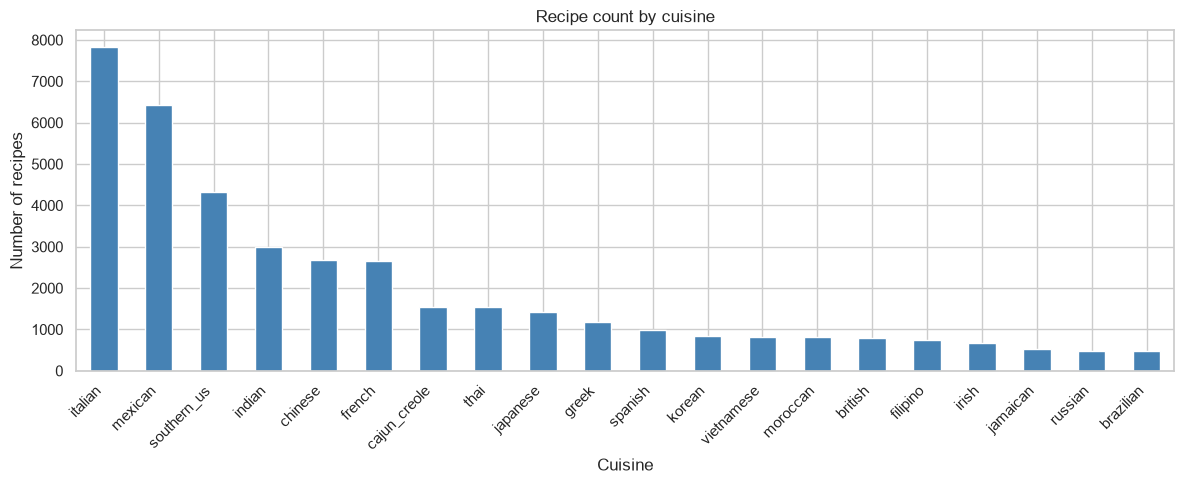

In [4]:
cuisine_counts = Counter(recipe['cuisine'] for recipe in recipes)
cuisine_df = pd.DataFrame(
    cuisine_counts.items(), columns=['cuisine', 'recipe_count']
).sort_values('recipe_count', ascending=False)

display(cuisine_df)

ax = cuisine_df.plot(
    kind='bar', x='cuisine', y='recipe_count', legend=False,
    figsize=(12, 5), color='steelblue'
)
ax.set_title('Recipe count by cuisine')
ax.set_xlabel('Cuisine')
ax.set_ylabel('Number of recipes')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


,ingredient,recipe_count
0,salt,18049
1,onions,7972
2,olive oil,7972
3,water,7457
4,garlic,7380
5,sugar,6434
6,garlic cloves,6237
7,butter,4848
8,ground black pepper,4785
9,all-purpose flour,4632


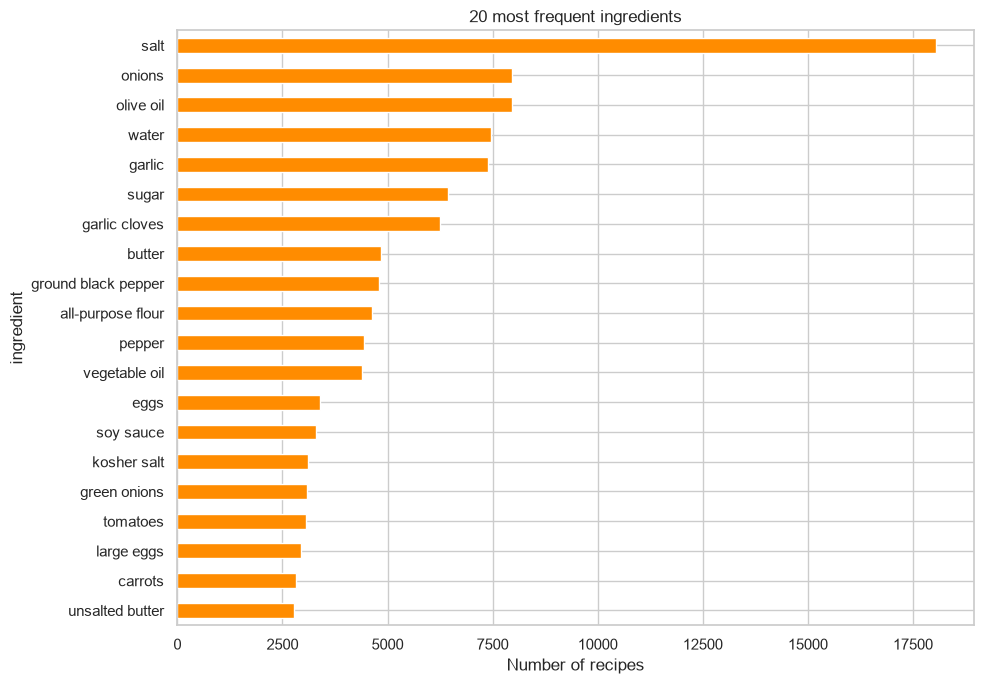

In [5]:
ingredient_counts = Counter(
    ingredient.strip().lower()
    for recipe in recipes
    for ingredient in recipe['ingredients']
)

ingredient_df = pd.DataFrame(
    ingredient_counts.most_common(20),
    columns=['ingredient', 'recipe_count']
)

display(ingredient_df)

ax = ingredient_df.sort_values('recipe_count').plot(
    kind='barh', x='ingredient', y='recipe_count', legend=False,
    figsize=(10, 7), color='darkorange'
)
ax.set_title('20 most frequent ingredients')
ax.set_xlabel('Number of recipes')
plt.tight_layout()
plt.show()


### Ingredient normalisation

The first preprocessing step is deliberately simple: lowercase each ingredient and remove surrounding spaces. Duplicate ingredients inside one recipe are removed. This also creates a reproducible text representation of each ingredient list.

In [6]:
def normalise_ingredients(recipe):
    ingredients = {
        ingredient.strip().lower()
        for ingredient in recipe['ingredients']
        if ingredient.strip()
    }
    return ' '.join(sorted(ingredients))

texts = [normalise_ingredients(recipe) for recipe in recipes]
y = np.array([recipe['cuisine'] for recipe in recipes])

print('Example of normalized text:')
print(texts[0])
print(f'Number of recipes: {len(texts):,}')


Example of normalized text:
black olives feta cheese crumbles garbanzo beans garlic grape tomatoes pepper purple onion romaine lettuce seasoning
Number of recipes: 39,774


## 5. Train, validation and test split

We use a fixed seed and stratification. The test set is kept untouched and will only be used for a final evaluation after model selection.

In [7]:
X_train, X_remaining, y_train, y_remaining = train_test_split(
    texts,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_remaining
)

print('Train:', len(X_train))
print('Validation:', len(X_val))
print('Test kept for final evaluation:', len(X_test))


Train: 27841
Validation: 5966
Test kept for final evaluation: 5967


## 6. Majority-class baseline

In [8]:
majority_baseline = DummyClassifier(strategy='most_frequent')
majority_baseline.fit(X_train, y_train)
majority_predictions = majority_baseline.predict(X_val)

print('Majority-class accuracy:', accuracy_score(y_val, majority_predictions))
print('Majority-class macro-F1:', f1_score(
    y_val, majority_predictions, average='macro', zero_division=0
))


Majority-class accuracy: 0.19711699631243715
Majority-class macro-F1: 0.016465975917110055


## 7. Main baseline: Multinomial Naive Bayes

TF-IDF is fitted inside the pipeline. This prevents information from the validation folds from leaking into the feature extraction step.

In [9]:
baseline_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        lowercase=True,
        token_pattern=r'(?u)\b[\w\-]+\b'
    )),
    ('classifier', MultinomialNB())
])

baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_val)

baseline_accuracy = accuracy_score(y_val, baseline_predictions)
baseline_macro_f1 = f1_score(
    y_val, baseline_predictions, average='macro', zero_division=0
)

print(f'Validation accuracy: {baseline_accuracy:.4f}')
print(f'Validation macro-F1: {baseline_macro_f1:.4f}')


Validation accuracy: 0.6695
Validation macro-F1: 0.4383


## 8. Per-class performance

In [10]:
print(classification_report(
    y_val,
    baseline_predictions,
    digits=3,
    zero_division=0
))


              precision    recall  f1-score   support

   brazilian      0.778     0.100     0.177        70
     british      1.000     0.050     0.094       121
cajun_creole      0.849     0.509     0.636       232
     chinese      0.586     0.903     0.711       401
    filipino      0.900     0.080     0.146       113
      french      0.512     0.418     0.460       397
       greek      0.855     0.267     0.407       176
      indian      0.750     0.909     0.822       450
       irish      0.778     0.070     0.128       100
     italian      0.644     0.904     0.752      1176
    jamaican      1.000     0.127     0.225        79
    japanese      0.921     0.545     0.684       213
      korean      0.952     0.323     0.482       124
     mexican      0.773     0.912     0.837       966
    moroccan      0.964     0.220     0.358       123
     russian      1.000     0.027     0.053        74
 southern_us      0.532     0.802     0.640       648
     spanish      0.824    

## 9. Confusion matrix

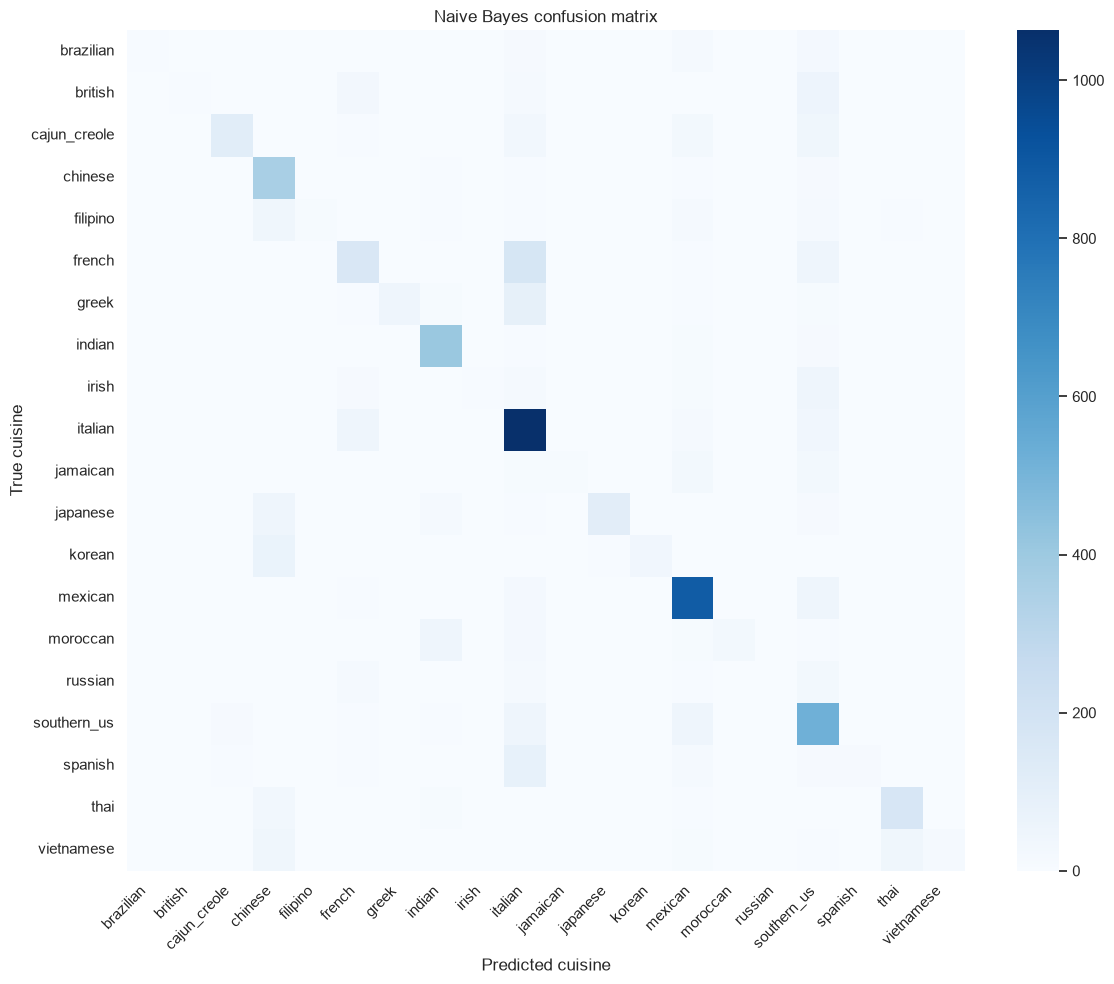

In [11]:
labels = sorted(set(y))
confusion = confusion_matrix(y_val, baseline_predictions, labels=labels)

plt.figure(figsize=(12, 10))
sns.heatmap(
    confusion,
    xticklabels=labels,
    yticklabels=labels,
    cmap='Blues',
    fmt='d',
    cbar=True
)
plt.xlabel('Predicted cuisine')
plt.ylabel('True cuisine')
plt.title('Naive Bayes confusion matrix')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### Most confused cuisine pairs

In [12]:
confused_pairs = []
label_to_index = {label: index for index, label in enumerate(labels)}

for true_index, true_label in enumerate(labels):
    for predicted_index, predicted_label in enumerate(labels):
        if true_index == predicted_index:
            continue
        count = confusion[true_index, predicted_index]
        if count:
            confused_pairs.append((count, true_label, predicted_label))

for count, true_label, predicted_label in sorted(confused_pairs, reverse=True)[:10]:
    print(f'{true_label} -> {predicted_label}: {count}')


french -> italian: 176
greek -> italian: 93
spanish -> italian: 84
korean -> chinese: 69
british -> southern_us: 57
moroccan -> indian: 53
italian -> french: 52
southern_us -> mexican: 51
japanese -> chinese: 48
irish -> southern_us: 48


## 10. Cross-validation on the training set

In [13]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = cross_validate(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring={'accuracy': 'accuracy', 'macro_f1': 'f1_macro'},
    n_jobs=-1,
    return_train_score=False
)

for metric in ('test_accuracy', 'test_macro_f1'):
    values = cv_results[metric]
    print(f'{metric}: mean={values.mean():.4f}, std={values.std():.4f}')


test_accuracy: mean=0.6553, std=0.0035
test_macro_f1: mean=0.4166, std=0.0053


## 11. Week 2 conclusion

At this stage, record: 

- the training, validation and test set sizes;
- the majority-class baseline;
- the TF-IDF + Multinomial Naive Bayes accuracy and macro-F1;
- the cross-validation mean and standard deviation;
- the cuisine pairs that are most frequently confused;
- the limitations caused by class imbalance and overlapping ingredient lists.

**Important:** do not tune the model or evaluate the test set to improve the Week 2 result. The test set should remain untouched until final model comparison.